# What Predicts Successful Airbnb Bookings?
### Airbnb project option: worked example notebook

**Module:** BU7154 Foundations of Business Analytics, Trinity Business School
**Worked example:** Dublin listings from InsideAirbnb (snapshot of 17 September 2026)
**Demonstration seed:** `BU7154DEMO`

**Business question.** A host-support team at Airbnb wants to know which features of a listing and its host predict successful bookings, and whether the predictors found by past research across many cities also hold in the cities you study. Airbnb does not publish bookings, so the number of guest reviews is used as a proxy (Biswas et al., 2020; Sengupta et al., 2021).

**How this notebook is organised**

| Step | What it does | Cells |
|---|---|---|
| 1 | Read the InsideAirbnb files from Drive and check what is in them | Settings, 1 to 4 |
| 2 | Draw a reproducible sample if needed, save working copies, take a first look | 5, 6, 7 |
| 3 | Turn review-level data into listing-level variables and join the two files | 8, 8b, 9 |
| 4 | Build the variables in the brief and look at how they relate to reviews | 10, 11, 12 |
| 4b | Text-mining variables from listing descriptions and reviews (stronger submission) | 13, 14 |
| 5 | Prepare the model data: missing values, standardising, overlap | 15 |
| 6 | Count models: Poisson vs Negative Binomial | 16, 17, 18 |
| 7 | Robustness: log-linear model and hurdle model | 19, 20 |

**Before you start**
1. On https://insideairbnb.com/get-the-data/ find your city and note the snapshot date. Download `listings.csv.gz` and `reviews.csv.gz` from the **data** links (not the plain `.csv` files under visualisations). Do not unzip them.
2. In Google Drive, create a folder called `airbnb_project` and upload both files into it from your computer. Do not use a shortcut to a file elsewhere in your Drive.
3. Fill in the **Settings** cell with your city, the snapshot date, your download date and your group seed: `BU7154G` followed by your group number, for example `BU7154G07`.
4. Run the cells in order. From Step 2 onwards, each step saves its output to Drive. After a restart, run the Settings cell and continue from the step you were on.

---
## Step 1: Getting the data

InsideAirbnb publishes two files per city that we need: `listings.csv.gz`, **one row per listing** with host, property, price and review-score fields, and `reviews.csv.gz`, **one row per guest review** with its date and text. Both refresh roughly every quarter, so your data will not match anyone else's.

Field definitions come from the official **Inside Airbnb Data Dictionary** (link in the brief). Cite it, and report which version you used: the schema changes over time.

### Settings
The only cell you edit. It also connects Google Drive and defines a small helper, `path()`, that names every file this notebook saves (for example `Dublin_features.csv.gz`).

In [1]:
# Settings: run this cell first, and again after any restart
import os, hashlib
import numpy as np, pandas as pd
import cities

CITY          = os.environ.get("CITY", "London")   # "London" or "Paris"; run_all.sh sets this for each city
SNAPSHOT_DATE = cities.snapshot(CITY)        # date shown on InsideAirbnb (see cities.py)
DOWNLOAD_DATE = cities.download_date(CITY)   # the day the files were downloaded
SEED          = "BU7154G11"       # BU7154G + group number
MAX_LISTINGS  = 50000             # upper limit for the analysis dataset (see the brief)

FOLDER = f"../data/{CITY}"
TABLES = os.environ.get("TABLES", "../outputs/tables")   # run_atlas.sh sends the other cities' tables to a subfolder
assert os.path.isdir(FOLDER), f"No data folder for {CITY}: run get_data.py first"
os.makedirs(TABLES, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEED_INT = int(hashlib.md5(SEED.encode()).hexdigest(), 16) % (2**32)   # the text seed as a number
def path(name):
    return os.path.join(FOLDER, f"{CITY}_{name}")

def save_table(df, name):
    df.to_csv(os.path.join(TABLES, f"{CITY}_{name}.csv"))

### Cell 1: Check the files are in Drive
If a file is not found, check the folder name and spelling, and that you uploaded the file itself rather than a shortcut. If you uploaded files after mounting Drive, run the Settings cell again.

In [2]:
# Cell 1: check the two InsideAirbnb files are in Drive
for f in ["listings.csv.gz", "reviews.csv.gz"]:
    p = os.path.join(FOLDER, f)
    if os.path.exists(p):
        print(f"{f:18s} found, {os.path.getsize(p)/1e6:,.1f} MB")
    else:
        print(f"{f:18s} NOT FOUND in {FOLDER}")

listings.csv.gz    found, 2.9 MB
reviews.csv.gz     found, 15.1 MB


### Cell 2: Load the listings file
Pandas reads the compressed file directly. The cell warns you if you downloaded the summary file by mistake: the summary `listings.csv` has no `amenities` column.

In [3]:
# Cell 2: load the listings file (one row per listing)
listings = pd.read_csv(os.path.join(FOLDER, "listings.csv.gz"), low_memory=False)
print(f"listings.csv.gz: {listings.shape[0]:,} rows, {listings.shape[1]} columns")
if "amenities" not in listings.columns:
    print("WARNING: no 'amenities' column. This looks like the summary listings.csv, not listings.csv.gz.")
print("Dates scraped:", sorted(listings["last_scraped"].unique()))

listings.csv.gz: 6,614 rows, 90 columns
Dates scraped: ['2026-09-25']


**Questions for your report**
- How many rows and columns does your file have? What does one row represent?
- Open the Data Dictionary. Which version are you using, and which columns in your file does it not describe?

### Cell 3: Load the reviews file
The summary `reviews.csv` has only `listing_id` and `date`; the detailed `reviews.csv.gz` also has the review text (`comments`).

In [4]:
# Cell 3: load the reviews file (one row per review)
reviews = pd.read_csv(os.path.join(FOLDER, "reviews.csv.gz"))
print(f"reviews.csv.gz: {reviews.shape[0]:,} rows, {reviews.shape[1]} columns")
print("Columns:", list(reviews.columns))
if "comments" not in reviews.columns:
    print("WARNING: no 'comments' column. This looks like the summary reviews.csv, not reviews.csv.gz.")

preview = reviews[["listing_id", "date", "comments"]].head(3).copy()
preview["comments"] = preview["comments"].str[:100] + "..."
print(preview.to_string())

reviews.csv.gz: 122,715 rows, 6 columns
Columns: ['listing_id', 'id', 'date', 'reviewer_id', 'reviewer_name', 'comments']
   listing_id        date                                                                                                 comments
0       72571  2011-02-26  Brenden is really helpful to us. We had a really pleasant stay in this place, the location is excell...
1       72571  2011-03-06  overall the location was great. however, the apartment is super small and we saw some cockroaches ou...
2       72571  2011-03-22  Brendan's place is awesome. Yes, it's a bit small but the area is amazing, is so close to everything...


**Questions for your report**
- What does one row of the reviews file represent, and how is that different from the listings file?
- Which column links the two files?

### Cell 4: Check the brief's variables in your city
Before building anything, check that each variable in the brief actually has data. Several fields used in past studies are empty in recent InsideAirbnb files.

In [5]:
# Cell 4: share of missing values for every variable in the brief
brief_vars = ["host_is_superhost", "host_response_time", "host_total_listings_count",
              "accommodates", "amenities", "price",
              "review_scores_rating", "review_scores_communication", "review_scores_cleanliness",
              "instant_bookable", "first_review", "last_review", "number_of_reviews",
              # possible substitutes
              "host_listings_count", "hosts_time_as_host_years", "host_since"]
check = pd.DataFrame({
    "in_file": [v in listings.columns for v in brief_vars],
    "share_missing": [listings[v].isna().mean().round(3) if v in listings.columns else None for v in brief_vars],
}, index=brief_vars)
print(check.to_string())
save_table(check, "missing_fields")

                             in_file  share_missing
host_is_superhost               True          0.000
host_response_time              True          1.000
host_total_listings_count       True          1.000
accommodates                    True          0.000
amenities                       True          0.000
price                           True          0.153
review_scores_rating            True          0.436
review_scores_communication     True          0.436
review_scores_cleanliness       True          0.436
instant_bookable                True          1.000
first_review                    True          0.436
last_review                     True          0.436
number_of_reviews               True          0.000
host_listings_count             True          0.000
hosts_time_as_host_years        True          0.000
host_since                      True          1.000


**Questions for your report**
- Which variables in the brief are completely or mostly empty in your city's file?
- For each, is there another column that could stand in for it? Check the Data Dictionary before you decide, and record the decision.

---
## Step 2: Sampling, saving and a first look

**Three decisions behind Cell 5**
1. **Sample listings, not reviews.** The listing is the unit of analysis; its reviews follow it.
2. **Use a random sample with your seed, never the first rows.** The file is sorted by listing ID, so the first rows are the oldest listings, which have far more reviews than the rest.
3. **Do not drop zero-review listings.** Listings that have never been reviewed are exactly the ones the business question is most interested in.

Dublin is well under the 50,000-listing limit, so it keeps every listing. London and the large US cities will probably need the sample.

### Cell 5: Draw a sample if the city is large, and save working copies
Colab deletes its own files when the session ends, so the two working files go to Drive.

In [6]:
# Cell 5: sample listings if needed, keep their reviews, save to Drive
n_raw = len(listings)
if n_raw > MAX_LISTINGS:
    listings_s = listings.sample(n=MAX_LISTINGS, random_state=SEED_INT)
    print(f"{n_raw:,} listings is above {MAX_LISTINGS:,}: drew a random sample with seed {SEED}")
else:
    listings_s = listings.copy()
    print(f"{n_raw:,} listings is within the limit: keeping all of them")

reviews_s = reviews[reviews["listing_id"].isin(listings_s["id"])]
print(f"Reviews kept for these listings: {len(reviews_s):,} of {len(reviews):,}")

first5k = listings.head(5000)["number_of_reviews"].mean()
rest    = listings.iloc[5000:]["number_of_reviews"].mean()
print(f"Mean reviews, first 5,000 rows of the file: {first5k:.1f}; all other rows: {rest:.1f}")

listings_s.to_csv(path("listings_step1.csv.gz"), index=False)
reviews_s.to_csv(path("reviews_step1.csv.gz"), index=False)
print("Saved:", sorted(f for f in os.listdir(FOLDER) if "step1" in f and f.startswith(CITY)))

6,614 listings is within the limit: keeping all of them
Reviews kept for these listings: 122,715 of 122,715
Mean reviews, first 5,000 rows of the file: 22.4; all other rows: 6.6


Saved: ['Hong Kong_listings_step1.csv.gz', 'Hong Kong_reviews_step1.csv.gz']


### Cell 6: The data log
The brief asks for the download date and the row counts at each stage, because InsideAirbnb refreshes its files every quarter. Copy this log into your report.

In [7]:
# Cell 6: data log
log = pd.Series({
    "City": CITY, "Snapshot date (InsideAirbnb)": SNAPSHOT_DATE, "Download date": DOWNLOAD_DATE,
    "Seed": SEED,
    "listings.csv.gz raw rows": f"{len(listings):,}", "reviews.csv.gz raw rows": f"{len(reviews):,}",
    "Listings after sampling": f"{len(listings_s):,}", "Reviews after sampling": f"{len(reviews_s):,}",
})
print(log.to_string())
log.to_csv(path("data_log.csv"), header=False)
save_table(log.rename("value").to_frame(), "data_log")

City                             Hong Kong
Snapshot date (InsideAirbnb)    2026-09-20
Download date                   2026-11-25
Seed                             BU7154G11
listings.csv.gz raw rows             6,614
reviews.csv.gz raw rows            122,715
Listings after sampling              6,614
Reviews after sampling             122,715


### Cell 7: A first look at the data
Before any modelling, look at the data. Four charts, each with a lesson for later steps.

Listings with zero reviews: 43.6%
Mean 18.6, variance 2,588.9, variance/mean 139.5


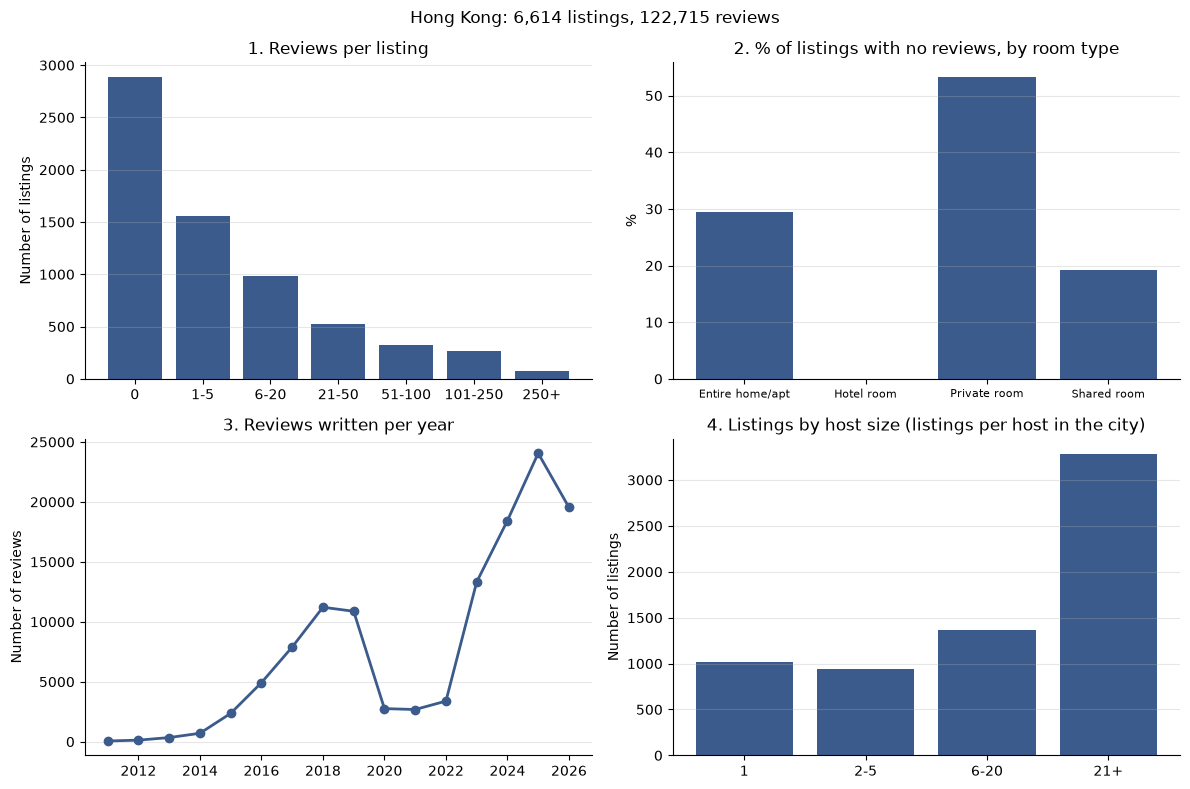

Room types: {'Private room': 4003, 'Entire home/apt': 2496, 'Shared room': 99, 'Hotel room': 16}
Reviews per year: {2011: 58, 2012: 129, 2013: 345, 2014: 703, 2015: 2363, 2016: 4923, 2017: 7894, 2018: 11216, 2019: 10878, 2020: 2760, 2021: 2684, 2022: 3386, 2023: 13321, 2024: 18445, 2025: 24061, 2026: 19549}
Listings by host size: {'1': 1022, '2-5': 944, '6-20': 1364, '21+': 3284}


In [8]:
# Cell 7: a first look at the data
import matplotlib.pyplot as plt
COLOR = "#3b5b8c"

L = pd.read_csv(path("listings_step1.csv.gz"), low_memory=False)
R = pd.read_csv(path("reviews_step1.csv.gz"), usecols=["listing_id", "date"])
y = L["number_of_reviews"]
print(f"Listings with zero reviews: {(y == 0).mean():.1%}")
print(f"Mean {y.mean():.1f}, variance {y.var():,.1f}, variance/mean {y.var()/y.mean():.1f}")

fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# 1. How many reviews do listings have?
labels = ["0", "1-5", "6-20", "21-50", "51-100", "101-250", "250+"]
binned = pd.cut(y, [-1, 0, 5, 20, 50, 100, 250, np.inf], labels=labels).value_counts().reindex(labels)
ax[0, 0].bar(labels, binned.values, color=COLOR)
ax[0, 0].set_title("1. Reviews per listing"); ax[0, 0].set_ylabel("Number of listings")

# 2. Share of listings never reviewed, by room type
z = L.groupby("room_type")["number_of_reviews"].apply(lambda s: 100 * (s == 0).mean())
ax[0, 1].bar(z.index, z.values, color=COLOR)
ax[0, 1].set_title("2. % of listings with no reviews, by room type"); ax[0, 1].set_ylabel("%")
ax[0, 1].tick_params(axis="x", labelsize=8)

# 3. Reviews written per year
years = pd.to_datetime(R["date"]).dt.year.value_counts().sort_index()
ax[1, 0].plot(years.index, years.values, color=COLOR, linewidth=2, marker="o")
ax[1, 0].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax[1, 0].set_title("3. Reviews written per year"); ax[1, 0].set_ylabel("Number of reviews")

# 4. Listings by how many listings their host has in this city
hb = pd.cut(L["calculated_host_listings_count"], [0, 1, 5, 20, np.inf],
            labels=["1", "2-5", "6-20", "21+"]).value_counts().sort_index()
ax[1, 1].bar(hb.index.astype(str), hb.values, color=COLOR)
ax[1, 1].set_title("4. Listings by host size (listings per host in the city)"); ax[1, 1].set_ylabel("Number of listings")

for a in ax.flat:
    a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", alpha=0.3)
fig.suptitle(f"{CITY}: {len(L):,} listings, {len(R):,} reviews")
plt.tight_layout()
plt.savefig(path("first_look.png"), dpi=150)
plt.show()
print("Room types:", L["room_type"].value_counts().to_dict())
print("Reviews per year:", years.to_dict())
print("Listings by host size:", hb.to_dict())

---
## Step 3: From reviews to listings

The reviews file has one row per review; the analysis needs one row per listing. Two jobs:
1. **Clean the comment text and detect its language** (Cell 8). Comments contain HTML tags such as `<br/>`, and many are not in English. Your second city's comments must be translated before they can be scored (Cell 8b).
2. **Aggregate to one row per listing and join** to the listings file on `listings.id = reviews.listing_id` (Cell 9).

### Cell 8: Clean the comments and detect their language
`py3langid` labels each comment with a language code. Expect about a minute for 400,000 comments.

In [9]:
# Cell 8: clean the comment text and detect each comment's language
import re
import py3langid

R = pd.read_csv(path("reviews_step1.csv.gz"))

def clean(text):
    text = re.sub(r"<[^>]+>", " ", str(text))          # HTML tags such as <br/>
    return re.sub(r"\s+", " ", text).strip()

R["text"]  = R["comments"].fillna("").map(clean)
R["words"] = R["text"].str.split().str.len()
R["lang"]  = [py3langid.classify(t)[0] if t else "none" for t in R["text"]]
R["is_en"] = (R["lang"] == "en").astype(int)

print(f"Empty comments: {(R['text'] == '').sum():,}")
print("Share of reviews by language (top 8):")
print(R["lang"].value_counts(normalize=True).head(8).round(3).to_string())
save_table(R["lang"].value_counts(normalize=True).rename("share").to_frame(), "language_share")

R[["id", "listing_id", "date", "text", "words", "lang", "is_en"]].to_csv(path("reviews_clean.csv.gz"), index=False)
print("Saved:", f"{CITY}_reviews_clean.csv.gz")

Empty comments: 18
Share of reviews by language (top 8):
lang
en     0.578
zh     0.300
ko     0.035
fr     0.013
yue    0.011
ja     0.010
de     0.009
es     0.006


Saved: Hong Kong_reviews_clean.csv.gz


**Questions for your report**
- Read ten comments the detector labels as not English. Are the labels right? Where does it go wrong?
- What share of your second city's comments is in English? How many would you need to translate?

### Cell 8b (second city only): Translate comments into English
Not run for London. For Paris, a random sample of non-English comments is translated offline with Argos Translate: free, no account, and the same input always gives the same translation, so a rerun reproduces it exactly. Models are downloaded once per language. The translated sample is saved and committed, so this cell only translates when that file is missing. **Record the tool, the version, the date and the number of comments translated** (the cell writes them to `Paris_translation_log.csv`).

In [10]:
# Cell 8b (second city only): translate a random sample of non-English comments with Argos Translate (offline, free)
RUN_TRANSLATION = CITY == "Paris"
N_TRANSLATE     = 2000        # random sample of non-English comments
MIN_COMMENTS    = 10          # download a language's model (~100 MB) only if the sample has this many comments in it

out = path("translated_sample.csv.gz")
if RUN_TRANSLATION and not os.path.exists(out):
    import importlib.metadata
    import argostranslate.package, argostranslate.translate

    R = pd.read_csv(path("reviews_clean.csv.gz"), keep_default_na=False)
    todo = R[(R["is_en"] == 0) & (R["text"] != "")].sample(n=N_TRANSLATE, random_state=SEED_INT)

    # One offline model per language into English, downloaded once and reused
    counts = todo["lang"].value_counts()
    argostranslate.package.update_package_index()
    models = {p.from_code: p for p in argostranslate.package.get_available_packages() if p.to_code == "en"}
    langs = [l for l in counts[counts >= MIN_COMMENTS].index if l in models]
    installed = {p.from_code for p in argostranslate.package.get_installed_packages() if p.to_code == "en"}
    for lang in set(langs) - installed:
        argostranslate.package.install_from_path(models[lang].download())

    translated = []
    for i, (text, lang) in enumerate(zip(todo["text"], todo["lang"]), 1):
        translated.append(argostranslate.translate.translate(text, lang, "en") if lang in langs else "")
        if i % 200 == 0:
            print(f"{i:,} of {N_TRANSLATE:,}", flush=True)
    todo["text_en"] = translated
    todo.to_csv(out, index=False)
    pd.Series({"Tool": "Argos Translate (offline)", "Version": importlib.metadata.version("argostranslate"),
               "Date run": pd.Timestamp.today().date(), "Comments sampled": N_TRANSLATE,
               "Translated": (todo["text_en"] != "").sum(), "Languages translated": ", ".join(sorted(langs))}
              ).to_csv(path("translation_log.csv"), header=False)

if RUN_TRANSLATION:
    todo = pd.read_csv(out, keep_default_na=False)
    print(pd.read_csv(path("translation_log.csv"), header=None, index_col=0)[1].to_string())
    print(todo.loc[todo["text_en"] != "", ["lang", "text", "text_en"]].head(5).to_string())

**Questions for your report**
- Will you translate every comment, or a random sample? If a sample, how will you use it: to score sentiment for every listing, or to check whether leaving non-English comments out changes your results?
- Read ten translations next to the originals. Does translation keep the tone of the review?

## From here on, you write the code

The cells above give you working code for loading, checking and sampling the data and for cleaning the comments. From Cell 9 onwards, each cell has hints and questions but no code: aggregating the reviews, building the variables and fitting the models is the core of the project. Add your own code cells where it says **Your code here**, and keep the same file names so that later steps can read what earlier steps saved.

### Cell 9: Aggregate to one row per listing and join
Three summaries per listing: the number of comments, their mean length, and the share not in English. The join is a **left join from the listings**, so listings with no reviews stay in the data with a comment count of 0. The count from the reviews file is then checked against `number_of_reviews`.

**Your code here.** Hints:
- Read `path("listings_step1.csv.gz")` and `path("reviews_clean.csv.gz")`.
- Group the reviews by `listing_id` and compute, per listing: the number of comments, the mean of `words`, and the share of comments not in English. Named aggregations in `groupby(...).agg(...)` keep this readable.
- Left-join the result to the listings on `id = listing_id`, and fill the comment count with 0 for listings with no reviews.
- Cross-check: for what share of listings does your count equal `number_of_reviews`? Save the result as `path("listing_level.csv.gz")`.

In [11]:
# Cell 9: aggregate the reviews to one row per listing and left-join to the listings
L = pd.read_csv(path("listings_step1.csv.gz"), low_memory=False)
R = pd.read_csv(path("reviews_clean.csv.gz"), usecols=["id", "listing_id", "words", "is_en"])

per_listing = R.groupby("listing_id").agg(
    n_comments=("id", "size"),
    mean_words=("words", "mean"),
    share_en=("is_en", "mean"),
)
per_listing["share_non_en"] = 1 - per_listing.pop("share_en")

LL = L.merge(per_listing, left_on="id", right_index=True, how="left")
LL["n_comments"] = LL["n_comments"].fillna(0).astype(int)

diff = LL["n_comments"] - LL["number_of_reviews"]
print(f"Listings after the join: {len(LL):,} (same as before: {len(LL) == len(L)})")
print(f"Listings with at least one comment: {(LL['n_comments'] > 0).mean():.1%}")
print(f"Comment count equals number_of_reviews: {(diff == 0).mean():.1%}; "
      f"lower: {(diff < 0).mean():.1%}; higher: {(diff > 0).mean():.1%}")
print(f"Review ids that appear on more than one listing: {R['id'].duplicated(keep=False).sum():,} rows")

LL.to_csv(path("listing_level.csv.gz"), index=False)
print("Saved:", f"{CITY}_listing_level.csv.gz")

Listings after the join: 6,614 (same as before: True)
Listings with at least one comment: 56.4%
Comment count equals number_of_reviews: 100.0%; lower: 0.0%; higher: 0.0%
Review ids that appear on more than one listing: 324 rows


Saved: Hong Kong_listing_level.csv.gz


**Questions for your report**
- Why a left join rather than an inner join? What would an inner join do to the zero-review listings?
- If the count did not match for some listings, what might explain it?
- Some reviews appear on more than one listing. Open two such listings on Airbnb: what do they have in common? What does this mean for `number_of_reviews` as a measure of each listing's bookings?

---
## Step 4: Building the variables

Cell 10 turns raw fields into the variables in the brief. Each variable is tied to a source; where the brief's field is empty, the substitute is named.

| Brief variable | Variable in the data | How it is built | Source |
|---|---|---|---|
| Number of reviews (outcome) | `number_of_reviews` | As given; proxy for bookings | Biswas et al. (2020); Sengupta et al. (2021) |
| Superhost status | `superhost` | 1 if `host_is_superhost` is "t" | Both papers |
| Host tenure | `host_years` | `hosts_time_as_host_years` (`host_since` is empty) | Both papers ("host duration", "membership") |
| Host size | `log_host_listings` | log(1 + `host_listings_count`); `host_total_listings_count` is empty | Sengupta et al. (2021) |
| Host response time | none | Empty in the file; cannot be tested | Sengupta et al. (2021) |
| Instant booking | none | Empty in the file; cannot be tested | Both papers |
| Capacity | `accommodates` | As given | Sengupta et al. (2021) |
| Amenities | `n_amenities` | Number of items in the JSON list | Both papers |
| Entire home | `entire_home` | 1 if `room_type` is "Entire home/apt" | Biswas et al. (2020) |
| Price | `log_price`, `price_missing` | Text to number, log; missing prices filled with the median and flagged | Both papers |
| Guest review scores | `review_scores_rating`, `_communication`, `_cleanliness` | As given (reviewed listings only) | Sengupta et al. (2021) |
| Review spread | `log_spread` | log(1 + days between first and last review) | The brief |
| Review sentiment | `share_positive` | Share of English comments with VADER compound ≥ 0.05 | Biswas et al. (2020); Hutto & Gilbert (2014) |
| Comment length, language | `avg_words`, `share_non_en` | From Cell 9 | The brief |

**Two distinctions to keep in mind**
- **Host-generated vs guest-generated.** Host and listing features exist for every listing, including those never reviewed. Review scores, spread and sentiment exist **only after a first review**, so a model that uses them cannot say anything about zero-review listings.
- **Host tenure is not listing age.** A host who joined in 2015 may have listed this flat last month. The review spread is closer to how long the listing has been collecting reviews.

### Cell 10: Build the variables
Scoring several hundred thousand English comments with VADER takes a few minutes. The result is saved as `Dublin_features.csv.gz`.

**Your code here.** Hints:
- `superhost`: 1 if `host_is_superhost` is "t". Host tenure: `hosts_time_as_host_years`. Host size: log(1 + `host_listings_count`).
- `amenities` is a JSON list stored as text: `json.loads()` turns it into a Python list; count its items.
- `price` is text such as "$1,250.00": remove `$` and `,`, convert with `pd.to_numeric`, decide how to handle missing prices, and take the log.
- Review spread: convert `first_review` and `last_review` with `pd.to_datetime` and take the difference in days.
- Sentiment: score English comments with VADER (`SentimentIntensityAnalyzer`); a compound score of 0.05 or more counts as positive. Aggregate to the share of positive comments per listing and merge.
- Print the mean, SD, min, max and missing share of each variable, and save `path("features.csv.gz")`.

In [12]:
# Cell 10: build the brief's variables
import json
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

D = pd.read_csv(path("listing_level.csv.gz"), low_memory=False)
F = D[["id", "host_id", "number_of_reviews"]].copy()

F["superhost"]         = (D["host_is_superhost"] == "t").astype(int)
F["host_years"]        = D["hosts_time_as_host_years"]
F["log_host_listings"] = np.log1p(D["host_listings_count"])
F["accommodates"]      = D["accommodates"]
F["n_amenities"]       = D["amenities"].map(lambda a: len(json.loads(a)))
F["entire_home"]       = (D["room_type"] == "Entire home/apt").astype(int)

price = pd.to_numeric(D["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")
F["price"]         = price
F["price_missing"] = price.isna().astype(int)
F["log_price"]     = np.log(price.fillna(price.median()))

for s in ["rating", "communication", "cleanliness"]:
    F[f"review_scores_{s}"] = D[f"review_scores_{s}"]
spread_days = (pd.to_datetime(D["last_review"]) - pd.to_datetime(D["first_review"])).dt.days
F["log_spread"]     = np.log1p(spread_days)
F["n_comments"]     = D["n_comments"]
F["log_mean_words"] = np.log1p(D["mean_words"])
F["share_non_en"]   = D["share_non_en"]

# Sentiment of English comments (VADER is English-only); scores are cached because scoring takes minutes
sent_file = path("review_sentiment.csv.gz")
if os.path.exists(sent_file):
    S = pd.read_csv(sent_file)
else:
    R = pd.read_csv(path("reviews_clean.csv.gz"), keep_default_na=False, usecols=["listing_id", "text", "is_en"])
    R = R[(R["is_en"] == 1) & (R["text"] != "")]
    sia = SentimentIntensityAnalyzer()
    scores = [sia.polarity_scores(t) for t in R["text"]]
    S = pd.DataFrame({"listing_id": R["listing_id"].values,
                      "compound": [s["compound"] for s in scores],
                      "neg": [s["neg"] for s in scores]})
    S.to_csv(sent_file, index=False)

S["positive"] = (S["compound"] >= 0.05).astype(int)
sent = S.groupby("listing_id").agg(share_positive=("positive", "mean"), review_neg=("neg", "mean"))
F = F.merge(sent, left_on="id", right_index=True, how="left")

summary = F.drop(columns=["id", "host_id"]).describe().T[["mean", "std", "min", "max"]]
summary["missing"] = F.drop(columns=["id", "host_id"]).isna().mean()
print(summary.round(3).to_string())

F.to_csv(path("features.csv.gz"), index=False)
print("Saved:", f"{CITY}_features.csv.gz")

                                mean       std    min         max  missing
number_of_reviews             18.554    50.881  0.000     626.000    0.000
superhost                      0.121     0.326  0.000       1.000    0.000
host_years                     7.194     4.193  0.000      15.000    0.000
log_host_listings              3.288     1.822  0.693       6.144    0.000
accommodates                   2.616     2.069  1.000      16.000    0.000
n_amenities                   17.608    12.915  0.000      76.000    0.000
entire_home                    0.377     0.485  0.000       1.000    0.000
price                        837.981  2658.227  0.730  150100.000    0.153
price_missing                  0.153     0.360  0.000       1.000    0.000
log_price                      6.210     0.824 -0.315      11.919    0.000
review_scores_rating           4.512     0.672  1.000       5.000    0.436
review_scores_communication    4.684     0.575  1.000       5.000    0.436
review_scores_cleanliness

Saved: Hong Kong_features.csv.gz


### Cell 11: Which listings have no price?
A quarter of Dublin listings have no price. Before deciding how to handle them, check whether they differ from the others.

**Your code here.** Hints:
- Compare listings with and without a price on `availability_365`, `number_of_reviews` and `number_of_reviews_ltm` (medians are safer than means here).
- Look at the distribution of price itself: minimum, maximum, quartiles.

In [13]:
# Cell 11: do listings without a price differ from the others?
F = pd.read_csv(path("features.csv.gz"))
D = pd.read_csv(path("listing_level.csv.gz"), usecols=["id", "availability_365", "number_of_reviews_ltm", "price_quote_raw"])
F = F.merge(D, on="id")

cmp = F.groupby("price_missing").agg(
    listings=("id", "size"),
    median_availability_365=("availability_365", "median"),
    median_reviews=("number_of_reviews", "median"),
    median_reviews_ltm=("number_of_reviews_ltm", "median"),
    share_zero_reviews=("number_of_reviews", lambda s: (s == 0).mean()),
    share_superhost=("superhost", "mean"),
    share_entire_home=("entire_home", "mean"),
)
print(cmp.round(3).T.to_string())
save_table(cmp, "price_missing")

print("\nPrice distribution (listings with a price):")
print(F["price"].describe(percentiles=[.01, .25, .5, .75, .99]).round(1).to_string())

currency = F["price_quote_raw"].dropna().str.extract(r'"currency": "(\w+)"')[0]
print("\nCurrency in the price quote:", currency.value_counts().to_dict())

price_missing                   0         1
listings                 5603.000  1011.000
median_availability_365   293.000     0.000
median_reviews              1.000     1.000
median_reviews_ltm          0.000     0.000
share_zero_reviews          0.447     0.375
share_superhost             0.128     0.079
share_entire_home           0.351     0.524

Price distribution (listings with a price):
count      5603.0
mean        838.0
std        2658.2
min           0.7
1%          139.6
25%         232.6
50%         475.0
75%         918.0
99%        5000.0
max      150100.0

Currency in the price quote: {'HKD': 5776}


**Questions for your report**
- Are listings without a price similar to the others? Is price missing at random?
- What are your options: drop these listings, fill in a value, or add a missing-price indicator? What does each do to your sample?
- InsideAirbnb shows a `$` sign for every city. Check the Data Dictionary: in which currency is the price for your city?

### Cell 12: How do the features relate to the number of reviews?
A first look, **not a model**. Each panel shows the median number of reviews across groups of one variable.

**Your code here.** Hints:
- For four variables (superhost, amenities, price, host tenure), group listings into a few bands with `pd.cut` and plot the median number of reviews per band.
- Keep it descriptive: this is a first look, not a model.

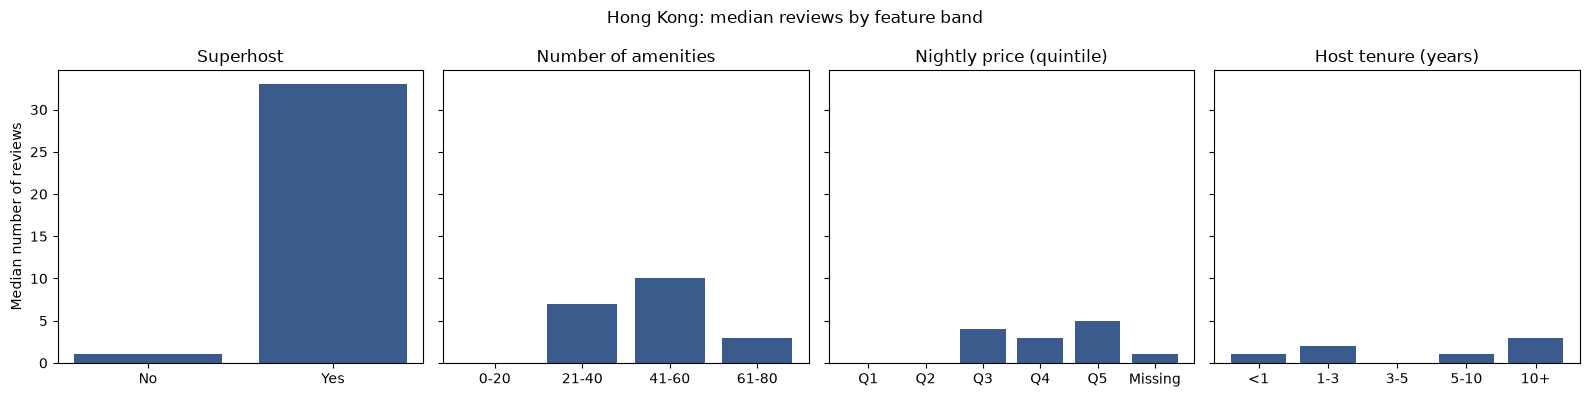

In [14]:
# Cell 12: median number of reviews across bands of four features (descriptive, not a model)
import matplotlib.pyplot as plt
COLOR = "#3b5b8c"
F = pd.read_csv(path("features.csv.gz"))

bands = {
    "Superhost": F["superhost"].map({0: "No", 1: "Yes"}),
    "Number of amenities": pd.cut(F["n_amenities"], [-1, 20, 40, 60, 80, np.inf], labels=["0-20", "21-40", "41-60", "61-80", "80+"]),
    "Nightly price (quintile)": pd.qcut(F["price"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]).cat.add_categories("Missing").fillna("Missing"),
    "Host tenure (years)": pd.cut(F["host_years"], [-1, 1, 3, 5, 10, np.inf], labels=["<1", "1-3", "3-5", "5-10", "10+"]),
}
fig, ax = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for a, (name, band) in zip(ax, bands.items()):
    med = F.groupby(band, observed=True)["number_of_reviews"].median()
    a.bar(med.index.astype(str), med.values, color=COLOR)
    a.set_title(name)
ax[0].set_ylabel("Median number of reviews")
fig.suptitle(f"{CITY}: median reviews by feature band")
fig.tight_layout()
fig.savefig(path("features_vs_reviews.png"), dpi=120)
plt.show()

---
## Step 4b: Text-mining variables (for a stronger submission)

Cell 10 built the variables in the brief. This step adds variables mined from text: the host's **listing title and description** (written before any guest arrives) and the guests' **reviews**. It is optional: a group can go straight to Step 5.

Both core papers mined the description as well as the reviews. Biswas et al. (2020) used the description's length, readability and superlatives, and the positive and negative sentiment of reviews; Sengupta et al. (2021) used the description's length and its positive and negative sentiment.

**Every variable has a tier. Say in your report which tier each of your variables belongs to.**

| Tier | Meaning | Variables |
|---|---|---|
| **[H] Hypothesis** | Used in the core papers, so you can state an expected direction | description length; description readability (LIX); promotional and superlative words; description positive and negative sentiment; host profile photo; host identity verified; review negativity; price relative to the neighbourhood median |
| **[E] Exploratory** | A transparent measure with no prior evidence in these papers; no expected direction | host "about me" text present; description is only Airbnb's legal host disclosure; share of reviews that mention the host by name |

**Three warnings before you start**
1. **The description is capped.** Airbnb's main description field holds about 500 characters, and many listings are at or near the limit. Description length is therefore censored: it cannot tell a host who wrote 500 characters from one who wanted to write 2,000.
2. **Some descriptions are not the host's words.** About 2% of Dublin descriptions are only Airbnb's legal disclosure ("…is solely responsible for offering this listing… they host as a business / as an individual"). Text measures of those listings describe Airbnb's wording, not the host's, so Cell 13 treats them as having no host description.
3. **Read what a word list catches.** Before trusting any variable, read 20 descriptions or reviews it flags.

Run order: **13 → 14.**

### Cell 13: Build the text variables
| Group | Variables | Tier | Source |
|---|---|---|---|
| A. Description | `log_desc_words`, `desc_lix`, `promo_rate`, `desc_pos`, `desc_neg`, `no_description` | [H] (`no_description` [E]) | Biswas et al. (2020); Sengupta et al. (2021); LIX: Björnsson (1968) |
| B. Host profile | `profile_pic`, `identity_verified` [H]; `host_about` [E] | mixed | Biswas et al. (2020); Ert et al. (2016) |
| C. Price position | `price_vs_area` | [H] | Sengupta et al. (2021): difference from the neighbourhood median |
| D. Reviews | `review_neg` (from Cell 10) [H]; `mentions_host` [E] | mixed | Biswas et al. (2020) |
| E. Disclosure | `legal_disclosure` | [E] | Description consists only of Airbnb's legal host text |

**Your code here.** Hints:
- Remove HTML from `description`. Flag descriptions that are only Airbnb's legal disclosure (they contain "is solely responsible for offering this listing") and treat them as having no host description.
- Description variables: word count (log), readability (LIX = words per sentence + 100 × share of words longer than six letters), promotional words per 100 words (write your own list and report it), VADER positive and negative proportions.
- Host profile: `host_has_profile_pic`, `host_identity_verified`, whether `host_about` has text.
- Price position: log price minus the median log price in the listing's `neighbourhood_cleansed`.
- Reviews: mean VADER negative proportion per listing; share of reviews that mention the host's first name.
- Save `path("features_text.csv.gz")`.

In [15]:
# Cell 13: text-mining variables from the listing description, host profile and reviews
import re
import py3langid
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

D = pd.read_csv(path("listing_level.csv.gz"), low_memory=False)
F = pd.read_csv(path("features.csv.gz"), usecols=["id", "log_price", "price_missing", "review_neg"])
sia = SentimentIntensityAnalyzer()

LEGAL = "is solely responsible for offering this listing"
PROMO = {"amazing", "stunning", "beautiful", "perfect", "luxury", "luxurious", "best", "unique", "exceptional",
         "spectacular", "gorgeous", "charming", "wonderful", "ideal", "fantastic", "incredible", "lovely",
         "stylish", "elegant", "exclusive", "breathtaking", "magnificent", "superb", "cosy", "cozy"}

def clean(text):
    return re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", str(text))).strip()

def lix(words, text):
    sentences = max(1, len(re.findall(r"[.!?]+", text)))
    return len(words) / sentences + 100 * sum(len(w) > 6 for w in words) / len(words)

desc = D["description"].fillna("").map(clean)
legal_only = desc.str.contains(LEGAL)
desc = desc.where(~legal_only, "")
desc_en = [bool(t) and py3langid.classify(t)[0] == "en" for t in desc]

T = D[["id"]].copy()
T["legal_only"]     = legal_only.astype(int)
T["no_description"] = (desc == "").astype(int)
T["desc_not_en"]    = [int(bool(t) and not e) for t, e in zip(desc, desc_en)]
T["log_desc_words"] = np.log1p(desc.str.split().str.len())

# Readability, promotional words and sentiment use English rules, so they are scored for English descriptions only
rows = []
for t, e in zip(desc, desc_en):
    words = re.findall(r"[a-z]+", t.lower())
    if not (e and words):
        rows.append((np.nan, np.nan, np.nan, np.nan))
        continue
    s = sia.polarity_scores(t)
    rows.append((lix(words, t), 100 * sum(w in PROMO for w in words) / len(words), s["pos"], s["neg"]))
T[["lix", "promo_per_100", "desc_pos", "desc_neg"]] = rows

T["has_profile_pic"]   = (D["host_has_profile_pic"] == "t").astype(int)
T["identity_verified"] = (D["host_identity_verified"] == "t").astype(int)
T["has_host_about"]    = D["host_about"].fillna("").str.strip().ne("").astype(int)

# Price relative to the neighbourhood median (0 = typical for the area; also 0 where the price is missing)
area = D["neighbourhood_cleansed"] if "neighbourhood_cleansed" in D else D["region_name"]   # country-wide files name regions
area_median = F["log_price"].where(F["price_missing"] == 0).groupby(area).transform("median")
T["price_vs_area"] = (F["log_price"] - area_median).where(F["price_missing"] == 0, 0)

# Reviews: share that mention the host's first name (all languages); review negativity comes from Cell 10
R = pd.read_csv(path("reviews_clean.csv.gz"), keep_default_na=False, usecols=["listing_id", "text"])
first_name = D.set_index("id")["host_name"].fillna("").str.split().str[0].str.lower()
names = R["listing_id"].map(first_name).fillna("")
R["mentions_host"] = [bool(n) and len(n) > 2 and re.search(rf"\b{re.escape(n)}\b", t.lower()) is not None
                      for n, t in zip(names, R["text"])]
T = T.merge(R.groupby("listing_id")["mentions_host"].mean().rename("share_mention_host"),
            left_on="id", right_index=True, how="left")
T["review_neg"] = F["review_neg"]

summary = T.drop(columns="id").describe().T[["mean", "std", "min", "max"]]
summary["missing"] = T.drop(columns="id").isna().mean()
print(summary.round(3).to_string())
print("Promotional words used:", sorted(PROMO))

T.to_csv(path("features_text.csv.gz"), index=False)
print("Saved:", f"{CITY}_features_text.csv.gz")

                      mean     std    min      max  missing
legal_only           0.000   0.017  0.000    1.000    0.000
no_description       0.004   0.066  0.000    1.000    0.000
desc_not_en          0.012   0.108  0.000    1.000    0.000
log_desc_words       3.919   0.734  0.000    5.257    0.000
lix                 44.170  18.874  2.000  194.514    0.016
promo_per_100        1.035   2.132  0.000   20.000    0.016
desc_pos             0.159   0.107  0.000    0.826    0.016
desc_neg             0.009   0.025  0.000    0.370    0.016
has_profile_pic      0.964   0.187  0.000    1.000    0.000
identity_verified    0.983   0.128  0.000    1.000    0.000
has_host_about       0.610   0.488  0.000    1.000    0.000
price_vs_area        0.092   0.816 -6.443    5.526    0.000
share_mention_host   0.183   0.257  0.000    1.000    0.436
review_neg           0.019   0.032  0.000    0.536    0.482
Promotional words used: ['amazing', 'beautiful', 'best', 'breathtaking', 'charming', 'cosy', 'cozy',

### Cell 14: Which text features go with more reviews, among hosts of similar tenure?
For every Step 4b variable, this compares the mean of log(1 + reviews) for listings **with** the feature (or above the median, for continuous variables) against listings **without** it (or below the median). To hold the strongest confounder roughly constant, the comparison is made **within three bands of host tenure** and then averaged. Bars to the right mean the feature goes with more reviews. Labels show each variable's tier.

This is still a descriptive comparison, not a model: it holds tenure roughly constant but nothing else.

**Your code here.** Hints:
- For each Step 4b variable, compare mean log(1 + reviews) for listings with the feature (or above the median) against those without (or below).
- Make the comparison within three bands of host tenure (`pd.qcut`) and average the gaps, so tenure is roughly held constant.
- Plot the gaps as horizontal bars, labelled with each variable's tier.

[H] identity_verified    -0.781
[H] desc_pos             -0.122
[H] desc_neg             -0.004
[H] lix                   0.057
[E] has_host_about        0.060
[H] review_neg            0.369
[H] log_desc_words        0.585
[H] promo_per_100         0.594
[H] has_profile_pic       0.765
[H] price_vs_area         0.818
[E] share_mention_host    1.023


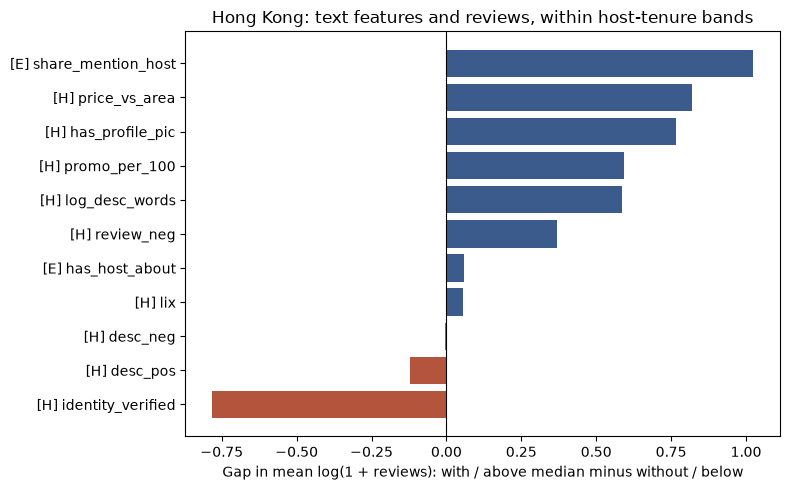

In [16]:
# Cell 14: gap in mean log(1 + reviews) with vs without each text feature, within host-tenure bands
import matplotlib.pyplot as plt
F = pd.read_csv(path("features.csv.gz"), usecols=["id", "number_of_reviews", "host_years"])
T = pd.read_csv(path("features_text.csv.gz"))
X = F.merge(T, on="id")
X["log_y"] = np.log1p(X["number_of_reviews"])
X["tenure_band"] = pd.qcut(X["host_years"].rank(method="first"), 3, labels=False)

TIERS = {"log_desc_words": "H", "lix": "H", "promo_per_100": "H", "desc_pos": "H", "desc_neg": "H",
         "has_profile_pic": "H", "identity_verified": "H", "review_neg": "H", "price_vs_area": "H",
         "has_host_about": "E", "legal_only": "E", "share_mention_host": "E"}

gaps = {}
for v, tier in TIERS.items():
    x = X[[v, "log_y", "tenure_band"]].dropna()
    x["high"] = x[v] > (0 if x[v].nunique() <= 2 else x[v].median())
    if x.groupby("tenure_band")["high"].nunique().min() < 2:   # no listings on one side in some band: no gap to measure
        continue
    by_band = x.groupby(["tenure_band", "high"])["log_y"].mean().unstack()
    gaps[f"[{tier}] {v}"] = (by_band[True] - by_band[False]).mean()

gaps = pd.Series(gaps).sort_values()
print(gaps.round(3).to_string())
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(gaps.index, gaps.values, color=["#b5543c" if g < 0 else "#3b5b8c" for g in gaps.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Gap in mean log(1 + reviews): with / above median minus without / below")
ax.set_title(f"{CITY}: text features and reviews, within host-tenure bands")
fig.tight_layout()
fig.savefig(path("text_feature_gaps.png"), dpi=120)
plt.show()

---
## Step 5: Preparing the model data

**Goal:** one clean table for the count models in Step 6.

1. **Missing price** (a quarter of listings): Cell 10 filled it with the median and added `price_missing`. If you choose differently, justify it in one sentence.
2. **Missing text variables:** listings with no host description have no readability or sentiment score. Fill with the median; `no_description` flags them.
3. **Variable sets:** the core set from Cell 10, and optionally the Step 4b set. State each variable's tier.
4. **Standardise** continuous predictors (`_z` = z-score), so their effects are per one standard deviation. Leave 0/1 variables as they are.
5. **Check overlap** between predictors: correlations above 0.5, and variance inflation factors (VIF) above 5.

### Cell 15: Prepare the model data

**Your code here.** Hints:
- Decide how to fill missing values in the text variables, and say why.
- Standardise each continuous predictor (subtract the mean, divide by the SD) and give it a `_z` suffix. Leave 0/1 variables as they are.
- List predictor pairs with |r| above 0.5 and compute VIFs (`variance_inflation_factor`, with a constant added).
- Report the zero share, mean and variance of `number_of_reviews`, and save `path("model_data.csv.gz")`.

In [17]:
# Cell 15: prepare the model data
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

M = pd.read_csv(path("features.csv.gz")).merge(
    pd.read_csv(path("features_text.csv.gz")).drop(columns="review_neg"), on="id")

CORE_CONT  = ["host_years", "log_host_listings", "accommodates", "n_amenities", "log_price"]
TEXT_CONT  = ["log_desc_words", "lix", "promo_per_100", "desc_pos", "desc_neg", "price_vs_area"]
GUEST_CONT = ["review_scores_rating", "review_scores_communication", "review_scores_cleanliness", "share_positive",
              "review_neg", "log_mean_words", "share_non_en", "log_spread", "share_mention_host"]
BINARY     = ["superhost", "entire_home", "price_missing", "no_description", "legal_only", "desc_not_en",
              "has_profile_pic", "identity_verified", "has_host_about"]

# Text scores are missing where there is no English description: fill with the median (flagged by no_description / desc_not_en).
# Guest-side variables stay missing: they exist only for reviewed listings and are used only in Model B.
for v in TEXT_CONT:
    M[v] = M[v].fillna(M[v].median())

core_missing = M[CORE_CONT].isna().any(axis=1)
print(f"Listings dropped for a missing core variable: {core_missing.sum()}")
M = M[~core_missing]

for v in CORE_CONT + TEXT_CONT + GUEST_CONT:
    M[f"{v}_z"] = (M[v] - M[v].mean()) / M[v].std()

r = M[CORE_CONT + TEXT_CONT + GUEST_CONT + BINARY].corr()
pairs = r.where(np.triu(np.ones(r.shape, dtype=bool), 1)).stack()
print("Predictor pairs with |r| > 0.5:")
print(pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).round(2).to_string())

def vif(cols, data):
    X = sm.add_constant(data[cols].dropna())
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=cols)

varying = [v for v in BINARY if M[v].std() > 0]
print("\nVIF, all-listing predictors (Models A and A+):")
print(vif(CORE_CONT + TEXT_CONT + varying, M).round(2).sort_values(ascending=False).to_string())
print("\nVIF, Model B predictors (reviewed listings):")
print(vif(CORE_CONT + GUEST_CONT + ["superhost", "entire_home", "price_missing"], M[M["number_of_reviews"] > 0]).round(2).sort_values(ascending=False).to_string())

y = M["number_of_reviews"]
print(f"\nnumber_of_reviews: zero share {(y == 0).mean():.3f}, mean {y.mean():.1f}, variance {y.var():,.1f}, variance/mean {y.var() / y.mean():.1f}")

M.to_csv(path("model_data.csv.gz"), index=False)
print("Saved:", f"{CITY}_model_data.csv.gz")

Listings dropped for a missing core variable: 0
Predictor pairs with |r| > 0.5:
log_price                    price_vs_area                  0.93
review_scores_rating         review_scores_cleanliness      0.85
                             review_scores_communication    0.78
review_scores_communication  review_scores_cleanliness      0.67
log_mean_words               share_non_en                  -0.61
share_positive               review_neg                    -0.60
review_scores_rating         share_positive                 0.58
                             review_neg                    -0.56
host_years                   has_host_about                 0.55
log_host_listings            log_price                     -0.53
accommodates                 log_price                      0.52
review_scores_cleanliness    review_neg                    -0.51
accommodates                 price_vs_area                  0.51
review_scores_communication  share_positive                 0.50

VIF, all-

Saved: Hong Kong_model_data.csv.gz


**Questions for your report**
- Which predictor pairs correlate above 0.5? Were any of them expected?
- Does any VIF exceed 5? Which variable would you keep in the main model, and which only for a robustness check?
- Compare the mean and variance of `number_of_reviews`. What does the ratio suggest for the choice of model?

---
## Step 6: Count models

**Goal:** explain the number of reviews with the variables from Steps 4 and 5, and choose between two count models.

| Model | Assumes | When it fits |
|---|---|---|
| **Poisson** | variance = mean | rarely, for review counts |
| **Negative Binomial** | variance can exceed the mean (an extra parameter, *alpha*) | counts with many zeros and a long tail |

**Three models**
- **Cell 16, Model A:** all listings, core host and listing features. The main model.
- **Cell 17, Model A+:** Model A plus the Step 4b variables that exist for every listing (stronger submission).
- **Cell 18, Model B:** reviewed listings only, adding the guest-side variables.

Standard errors are **clustered by host**, because many hosts have several listings.

**How to read an IRR (incidence rate ratio).** IRR = exp(coefficient). An IRR of 1.20 means the expected number of reviews is 20% higher; 0.80 means 20% lower. For a `_z` variable the change is per one standard deviation; for a 0/1 variable it is "feature present" against "absent", holding the other variables constant.

Reference: Cameron and Trivedi (2013) on count models.

### Cell 16: Model A, Poisson vs Negative Binomial

**Your code here.** Hints:
- Model A uses all listings and the core host and listing features.
- Fit `smf.poisson` and `smf.negativebinomial` with the same formula, standard errors clustered by `host_id` (`cov_type="cluster"`). If the Negative Binomial does not converge, start it from the Poisson estimates (`start_params`, with one extra value for alpha).
- Compare the two models on AIC, BIC and log-likelihood, and on the share of zero-review listings each predicts. For the Negative Binomial, the predicted probability of a zero is (1 + alpha × mu)^(-1/alpha).
- Print the Poisson and Negative Binomial IRRs side by side, then the Negative Binomial IRRs with 95% confidence intervals.

In [18]:
# Cell 16: Model A, Poisson vs Negative Binomial (all listings, core features)
import statsmodels.formula.api as smf
from scipy import stats
from models import CORE, formula, cluster, fit_nb, irr, stars
M = pd.read_csv(path("model_data.csv.gz"))

pois = smf.poisson(formula(CORE), M).fit(maxiter=200, disp=0, **cluster(M))
nbA  = fit_nb(CORE, M)

alpha = nbA.params["alpha"]
fit = pd.DataFrame({
    "Poisson": [pois.aic, pois.bic, pois.llf, np.exp(-pois.predict(M)).mean()],
    "Negative Binomial": [nbA.aic, nbA.bic, nbA.llf, ((1 + alpha * nbA.predict(M)) ** (-1 / alpha)).mean()],
}, index=["AIC", "BIC", "log-likelihood", "predicted share of zeros"])
print(fit.round(3).to_string())
print(f"Observed share of zeros: {(M['number_of_reviews'] == 0).mean():.3f};  NB alpha = {alpha:.3f};  "
      f"LR statistic for alpha = 0: {2 * (nbA.llf - pois.llf):,.0f}")

side = pd.DataFrame({"Poisson IRR": irr(pois)["IRR"].round(3).astype(str) + irr(pois)["p"].map(stars),
                     "NB IRR": irr(nbA)["IRR"].round(3).astype(str) + irr(nbA)["p"].map(stars)})
print("\n", side.to_string())
print("\nNegative Binomial, Model A (clustered by host):")
print(irr(nbA).round(3).to_string())

# Observed vs predicted distribution of reviews: the evidence for Negative Binomial over Poisson
labels = ["0", "1-5", "6-20", "21-50", "51-100", "101-250", "250+"]
uppers = [0, 5, 20, 50, 100, 250]
def bin_shares(cdf):
    return np.diff([0] + [cdf(u).mean() for u in uppers] + [1])
mu_p, mu_nb, n_nb = pois.predict(M), nbA.predict(M), 1 / alpha
count_fit = pd.DataFrame({
    "Observed": pd.cut(M["number_of_reviews"], [-1] + uppers + [np.inf], labels=labels).value_counts(normalize=True).reindex(labels).values,
    "Poisson": bin_shares(lambda u: stats.poisson.cdf(u, mu_p)),
    "Negative Binomial": bin_shares(lambda u: stats.nbinom.cdf(u, n_nb, n_nb / (n_nb + mu_nb))),
}, index=labels)
print("\nShare of listings by number of reviews, observed and predicted:")
print(count_fit.round(3).to_string())

save_table(fit, "model_fit")
save_table(irr(nbA), "model_a")
save_table(count_fit, "count_fit")

                             Poisson  Negative Binomial
AIC                       272123.139          37110.430
BIC                       272184.312          37178.400
log-likelihood           -136052.570         -18545.215
predicted share of zeros       0.009              0.440
Observed share of zeros: 0.436;  NB alpha = 3.882;  LR statistic for alpha = 0: 235,015

                     Poisson IRR    NB IRR
superhost              3.606***   3.31***
host_years_z           1.669***  1.919***
log_host_listings_z    0.511***  0.282***
accommodates_z         1.153***     1.076
n_amenities_z          1.222***   1.587**
entire_home            0.596***     0.594
log_price_z               0.939     1.474
price_missing             0.742     0.745

Negative Binomial, Model A (clustered by host):
                       IRR    low   high      p
superhost            3.310  1.993  5.496  0.000
host_years_z         1.919  1.422  2.591  0.000
log_host_listings_z  0.282  0.162  0.489  0.000
accommodate

**Questions for your report**

*Model choice*
- Which model has the lower AIC and BIC, and by how much?
- What share of listings has zero reviews, and how close does each model come to it?
- Compare the two coefficient columns. Which variables change significance, size or direction between Poisson and Negative Binomial? Both use clustered standard errors, so why do the estimates still differ?

*Interpretation (Negative Binomial)*
- Which three variables have the largest effects? Interpret each IRR in one sentence.
- Do superhost status, host tenure and amenities behave as Biswas et al. (2020) and Sengupta et al. (2021) found?
- What does the `price_missing` IRR tell you, given Cell 11?

### Cell 17 (stronger submission): Model A+, adding the Step 4b variables
Adds the description and host-profile variables to Model A. They all exist before a listing's first review, so they can be used for every listing. `price_vs_area` is left out because it almost duplicates `log_price` (Cell 15). The cell compares Model A+ with Model A on AIC and prints the Negative Binomial results.

**Your code here.** Hints:
- Add the Step 4b variables that exist for every listing to Model A. Leave out any variable that almost duplicates another (check Cell 15).
- Compare AIC with Model A fitted on the same listings, and report the IRRs.

In [19]:
# Cell 17: Model A+, Model A plus the Step 4b variables that exist for every listing
from models import TEXT, usable
TEXT = usable(M, TEXT)   # drop flags that (almost) never vary in this city

nbAplus = fit_nb(CORE + TEXT, M)
print(f"AIC, Model A: {nbA.aic:,.0f};  Model A+: {nbAplus.aic:,.0f};  improvement: {nbA.aic - nbAplus.aic:,.0f} "
      f"for {len(TEXT)} extra variables")
print("\nNegative Binomial, Model A+:")
print(irr(nbAplus).round(3).to_string())

# Robustness: price relative to the neighbourhood instead of log price
swap = [v if v != "log_price_z" else "price_vs_area_z" for v in CORE] + TEXT
nb_swap = fit_nb(swap, M)
print("\nIRR with log_price_z vs price_vs_area_z:")
print(pd.concat([irr(nbAplus)["IRR"].rename("log_price_z"), irr(nb_swap)["IRR"].rename("price_vs_area_z")], axis=1).round(3).to_string())

AIC, Model A: 37,110;  Model A+: 36,888;  improvement: 223 for 10 extra variables

Negative Binomial, Model A+:
                       IRR    low   high      p
superhost            3.317  2.057  5.349  0.000
host_years_z         1.844  1.358  2.504  0.000
log_host_listings_z  0.260  0.157  0.430  0.000
accommodates_z       1.118  0.935  1.337  0.221
n_amenities_z        1.455  1.136  1.865  0.003
entire_home          0.581  0.363  0.930  0.024
log_price_z          1.475  1.001  2.172  0.049
price_missing        0.847  0.543  1.322  0.464
has_profile_pic      1.532  0.781  3.006  0.215
identity_verified    0.688  0.275  1.724  0.425
has_host_about       1.472  0.879  2.465  0.141
no_description       2.137  0.755  6.046  0.152
desc_not_en          1.662  0.940  2.940  0.081
log_desc_words_z     1.158  1.003  1.338  0.046
lix_z                1.207  0.971  1.501  0.091
promo_per_100_z      0.927  0.829  1.037  0.185
desc_pos_z           0.989  0.852  1.148  0.884
desc_neg_z           0.8


IRR with log_price_z vs price_vs_area_z:
                     log_price_z  price_vs_area_z
superhost                  3.317            3.208
host_years_z               1.844            1.808
log_host_listings_z        0.260            0.252
accommodates_z             1.118            1.189
n_amenities_z              1.455            1.524
entire_home                0.581            0.621
log_price_z                1.475              NaN
price_missing              0.847            0.786
has_profile_pic            1.532            1.643
identity_verified          0.688            0.732
has_host_about             1.472            1.445
no_description             2.137            2.144
desc_not_en                1.662            1.615
log_desc_words_z           1.158            1.159
lix_z                      1.207            1.204
promo_per_100_z            0.927            0.938
desc_pos_z                 0.989            0.987
desc_neg_z                 0.836            0.830
price_vs

**Questions for your report**
- How much does AIC improve when the text variables are added? Is the improvement worth the extra variables?
- Which Step 4b variables are significant? Do the [H] variables go in the direction the papers report?
- Do the core effects (superhost, tenure, amenities, price) change when the text variables are added?
- *Robustness:* re-run with `price_vs_area_z` in place of `log_price_z`. Do the other results change?

### Cell 18: Model B, reviewed listings with guest-side variables
Adds review scores, sentiment, review negativity, comment length, language share and the review spread. These exist only for listings with at least one review, so the model is fitted on those listings alone.

**Your code here.** Hints:
- Model B uses reviewed listings only and adds the guest-side variables (review scores, sentiment, comment length, language share, review spread).
- Fit a Negative Binomial with clustered standard errors, check that it has converged, and report the IRRs.
- Fit it again without the review spread and compare.

In [20]:
# Cell 18: Model B, reviewed listings with guest-side variables
from models import GUEST

reviewed = M[M["number_of_reviews"] > 0]
B = reviewed.dropna(subset=GUEST)
print(f"Reviewed listings: {len(reviewed):,}; with every guest-side variable: {len(B):,} "
      f"(dropped {len(reviewed) - len(B):,}, mostly listings without a review score or an English comment)")

nbB    = fit_nb(CORE + GUEST, B)
nbB_ns = fit_nb(CORE + [g for g in GUEST if g != "log_spread_z"], B)
print(f"Converged: {nbB.mle_retvals['converged']};  AIC with spread {nbB.aic:,.0f}, without {nbB_ns.aic:,.0f}")
print("\nNegative Binomial, Model B:")
print(irr(nbB).round(3).to_string())
print("\nIRR with and without log_spread_z:")
print(pd.concat([irr(nbB)["IRR"].rename("with spread"), irr(nbB_ns)["IRR"].rename("without spread")], axis=1).round(3).to_string())

Reviewed listings: 3,731; with every guest-side variable: 3,428 (dropped 303, mostly listings without a review score or an English comment)


Converged: True;  AIC with spread 26,166, without 28,228

Negative Binomial, Model B:
                                 IRR    low   high      p
superhost                      1.985  1.654  2.382  0.000
host_years_z                   1.027  0.958  1.101  0.457
log_host_listings_z            0.819  0.719  0.932  0.002
accommodates_z                 1.118  1.058  1.182  0.000
n_amenities_z                  0.992  0.912  1.079  0.851
entire_home                    0.821  0.667  1.010  0.062
log_price_z                    0.918  0.840  1.003  0.059
price_missing                  0.725  0.575  0.913  0.006
review_scores_rating_z         1.052  0.924  1.197  0.443
review_scores_communication_z  1.171  1.059  1.295  0.002
review_scores_cleanliness_z    1.044  0.918  1.187  0.512
share_positive_z               0.978  0.912  1.048  0.526
review_neg_z                   0.960  0.893  1.033  0.277
log_mean_words_z               1.134  1.015  1.267  0.027
share_non_en_z                 1.343  1.187 

**Questions for your report**
- This model only includes listings with at least one review. Why does that matter for how you interpret it?
- `log_spread_z` measures how long a listing has been collecting reviews. What happens to host tenure once it is in the model? Re-run without it and compare.
- Compare the guest-side effects with Biswas et al. (2020) and Sengupta et al. (2021). Which findings hold in your city?
- If the optimiser reports that it has not converged, the estimates cannot be trusted. Try a different starting point or method before reading the table.

---
## Step 7: Robustness

**Why.** Two checks on Model A. The brief allows a log-linear model as a simpler alternative; and Sengupta et al. (2021) use a **hurdle model**, which treats "has this listing been reviewed at all?" and "how many reviews?" as separate questions.

**What Cells 19 and 20 do**
1. **Cell 19** fits OLS on log(1 + reviews) with the Model A predictors and puts its coefficients next to the Negative Binomial's.
2. **Cell 20** fits a hurdle model in two parts: a logit for having any review (all listings), and a zero-truncated Negative Binomial for the number of reviews among reviewed listings. Results are odds ratios for the first part and IRRs for the second.

Both cells use the data and Model A from Cell 16; after a restart, run the Settings cell and Cell 16 first.

### Cell 19: Log-linear alternative

**Your code here.** Hints:
- Fit OLS on log(1 + `number_of_reviews`) with the Model A predictors, standard errors clustered by host.
- Put the OLS and Negative Binomial coefficients side by side: same direction? significant in both, one or neither?

In [21]:
# Cell 19: log-linear alternative, OLS on log(1 + reviews) with the Model A predictors
M["log_y"] = np.log1p(M["number_of_reviews"])
ols = smf.ols(formula(CORE, "log_y"), M).fit(**cluster(M))

comp = pd.DataFrame({"OLS coef": ols.params, "OLS p": ols.pvalues, "NB coef": nbA.params, "NB p": nbA.pvalues}).loc[CORE]
comp["same direction"] = np.sign(comp["OLS coef"]) == np.sign(comp["NB coef"])
comp["significant at 5%"] = np.select([(comp["OLS p"] < .05) & (comp["NB p"] < .05), comp["OLS p"] < .05, comp["NB p"] < .05],
                                      ["both", "OLS only", "NB only"], "neither")
print(f"OLS R-squared: {ols.rsquared:.3f}")
print(comp.round(3).to_string())

OLS R-squared: 0.388
                     OLS coef  OLS p  NB coef   NB p  same direction significant at 5%
superhost               1.431  0.000    1.197  0.000            True              both
host_years_z            0.330  0.000    0.652  0.000            True              both
log_host_listings_z    -0.568  0.000   -1.268  0.000            True              both
accommodates_z          0.126  0.002    0.073  0.494            True          OLS only
n_amenities_z           0.355  0.000    0.462  0.001            True              both
entire_home            -0.262  0.018   -0.520  0.068            True          OLS only
log_price_z            -0.023  0.672    0.388  0.075           False           neither
price_missing          -0.137  0.205   -0.294  0.306            True           neither


**Questions for your report**
- Do the two models agree on the direction and significance of each predictor?
- Why is this a simplification relative to a count model? Think about what log(1 + y) does to the zeros.

### Cell 20: Hurdle model, any review vs how many

**Your code here.** Hints:
- Part 1: a logit model of whether a listing has any review at all (all listings).
- Part 2: a zero-truncated Negative Binomial of the number of reviews among listings with at least one (`TruncatedLFNegativeBinomialP` in `statsmodels`).
- Use the same predictors in both parts; report odds ratios for part 1 and IRRs for part 2.

In [22]:
# Cell 20: hurdle model, part 1 = any review (logit), part 2 = how many (zero-truncated Negative Binomial)
from statsmodels.discrete.truncated_model import TruncatedLFNegativeBinomialP

M["any_review"] = (M["number_of_reviews"] > 0).astype(int)
logit = smf.logit(formula(CORE, "any_review"), M).fit(disp=0, **cluster(M))

P = M[M["number_of_reviews"] > 0]
tnb = TruncatedLFNegativeBinomialP.from_formula(formula(CORE), P, truncation=0).fit(
    method="bfgs", maxiter=3000, disp=0, **cluster(P))
assert tnb.mle_retvals["converged"], "Truncated Negative Binomial did not converge"

hurdle = pd.DataFrame({
    "Part 1 odds ratio": np.exp(logit.params[CORE]), "Part 1 p": logit.pvalues[CORE],
    "Part 2 IRR": np.exp(tnb.params[CORE]), "Part 2 p": tnb.pvalues[CORE],
    "Model A IRR": np.exp(nbA.params[CORE]),
})
print(f"Part 1: {len(M):,} listings, {M['any_review'].mean():.1%} reviewed.  Part 2: {len(P):,} reviewed listings.")
print(hurdle.round(3).to_string())
save_table(irr(logit), "hurdle_any_review")
save_table(irr(tnb), "hurdle_how_many")

Part 1: 6,614 listings, 56.4% reviewed.  Part 2: 3,731 reviewed listings.
                     Part 1 odds ratio  Part 1 p  Part 2 IRR  Part 2 p  Model A IRR
superhost                        4.414     0.000       3.124     0.000        3.310
host_years_z                     1.469     0.001       1.769     0.000        1.919
log_host_listings_z              0.399     0.000       0.553     0.004        0.282
accommodates_z                   1.114     0.301       1.191     0.006        1.076
n_amenities_z                    2.200     0.000       1.176     0.152        1.587
entire_home                      0.810     0.327       0.645     0.099        0.594
log_price_z                      1.084     0.468       0.889     0.408        1.474
price_missing                    1.268     0.249       0.548     0.014        0.745


**Questions for your report**
- Which predictors matter for getting a first review, and which for getting many reviews? Are they the same?
- Which part is closer to the business question of a host-support team?
- Is your Step 6 conclusion **robust**? Write two sentences you could put in a limitations or robustness section.

---
## Step 8: Further analysis

Four additions to Steps 6 and 7. Cells 21 to 24 use the models from Cells 16 to 20; after a restart, run the Settings cell and Cells 16 to 20 first.

### Cell 21: Effects in reviews, not ratios
Each scenario changes one feature for every listing and averages the predicted reviews (Model A) and the predicted chance of at least one review (hurdle part 1).

In [23]:
# Cell 21: what Model A and the hurdle logit mean in reviews, for the levers a host controls
# Each scenario changes one feature for every listing and averages the predictions (other features as observed)
def scenario(change=None):
    X = M.copy()
    if change:
        change(X)
    return nbA.predict(X).mean(), logit.predict(X).mean()

sd_amen, sd_lp = M["n_amenities"].std(), M["log_price"].std()
priced = M["price_missing"] == 0

def superhost(v):
    def change(X):
        X["superhost"] = v
    return change

def more_amenities(X):
    X["n_amenities_z"] += 10 / sd_amen

def cheaper(X):
    X.loc[priced, "log_price_z"] += np.log(0.9) / sd_lp

rows = {"As observed": scenario(),
        "Nobody is a superhost": scenario(superhost(0)),
        "Everybody is a superhost": scenario(superhost(1)),
        "10 more amenities": scenario(more_amenities),
        "Price 10% lower": scenario(cheaper)}
effects = pd.DataFrame(rows, index=["Expected reviews", "P(at least one review)"]).T
effects["Reviews vs observed"] = (effects["Expected reviews"] / rows["As observed"][0] - 1).map("{:+.0%}".format)
print(effects.round(3).to_string())
save_table(effects, "scenarios")

                          Expected reviews  P(at least one review) Reviews vs observed
As observed                         35.556                   0.564                 +0%
Nobody is a superhost               22.263                   0.546                -37%
Everybody is a superhost            73.686                   0.781               +107%
10 more amenities                   50.839                   0.662                +43%
Price 10% lower                     33.972                   0.563                 -4%


### Cell 22: Robustness, recent activity
Lifetime `number_of_reviews` grows with a listing's age. `number_of_reviews_ltm` (last 12 months) measures current bookings.

In [24]:
# Cell 22: robustness, recent activity: reviews in the last 12 months instead of lifetime reviews
# Lifetime reviews reward listings for simply being old; number_of_reviews_ltm measures current bookings
M = M.merge(pd.read_csv(path("listing_level.csv.gz"), usecols=["id", "number_of_reviews_ltm"]), on="id")
y_ltm = M["number_of_reviews_ltm"]
print(f"Reviews in the last 12 months: zero share {(y_ltm == 0).mean():.3f}, mean {y_ltm.mean():.1f}, "
      f"variance/mean {y_ltm.var() / y_ltm.mean():.1f}")

nb_ltm = fit_nb(CORE, M, y="number_of_reviews_ltm")
ltm = pd.DataFrame({"Lifetime IRR": irr(nbA)["IRR"].round(3).astype(str) + irr(nbA)["p"].map(stars),
                    "Last 12 months IRR": irr(nb_ltm)["IRR"].round(3).astype(str) + irr(nb_ltm)["p"].map(stars)})
print(ltm.to_string())
save_table(irr(nb_ltm), "model_ltm")

Reviews in the last 12 months: zero share 0.625, mean 4.2, variance/mean 26.4
                    Lifetime IRR Last 12 months IRR
superhost                3.31***           5.034***
host_years_z            1.919***              1.024
log_host_listings_z     0.282***           0.396***
accommodates_z             1.076              1.137
n_amenities_z            1.587**           1.644***
entire_home                0.594              0.872
log_price_z                1.474                1.1
price_missing              0.745           0.346***


### Cell 23: Listing segments
k-means on listing characteristics, with the number of segments chosen by silhouette score, then Model A within each segment. Biswas et al. (2020) clustered cities by number of listings; segmenting listings is our extension.

In [25]:
# Cell 23: segment listings with k-means and fit Model A within each segment
# (Biswas et al., 2020 clustered cities by size, not listings: this is our own extension)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from models import usable

SEGMENT_VARS = ["accommodates_z", "n_amenities_z", "log_price_z", "entire_home", "log_host_listings_z"]
X = M[SEGMENT_VARS].to_numpy()

sample = np.random.default_rng(SEED_INT).choice(len(X), min(10000, len(X)), replace=False)
silhouette = {k: silhouette_score(X[sample], KMeans(k, n_init=10, random_state=SEED_INT).fit_predict(X[sample]))
              for k in range(2, 7)}
K = max(silhouette, key=silhouette.get)
print("Silhouette by number of clusters:", {k: round(s, 3) for k, s in silhouette.items()}, "-> K =", K)

M["segment"] = KMeans(K, n_init=10, random_state=SEED_INT).fit_predict(X)
profile = M.groupby("segment").agg(
    listings=("id", "size"), accommodates=("accommodates", "mean"), amenities=("n_amenities", "mean"),
    median_price=("price", "median"), entire_home=("entire_home", "mean"), host_listings=("log_host_listings", lambda s: np.expm1(s).median()),
    superhost=("superhost", "mean"), zero_reviews=("number_of_reviews", lambda s: (s == 0).mean()),
    median_reviews=("number_of_reviews", "median"))
print(profile.round(2).to_string())
save_table(profile, "segments")

by_segment = {}
for s, d in M.groupby("segment"):
    try:
        t = irr(fit_nb(usable(d, CORE), d))
    except (AssertionError, np.linalg.LinAlgError):   # a small or uniform segment cannot support the model
        continue
    by_segment[f"Segment {s}"] = t["IRR"].round(3).astype(str) + t["p"].map(stars)
print("\nNegative Binomial IRR by segment:")
by_segment = pd.DataFrame(by_segment).reindex(CORE).fillna("-")
print(by_segment.to_string())
save_table(by_segment, "segment_irr")

Silhouette by number of clusters: {2: 0.3, 3: 0.339, 4: 0.319, 5: 0.328, 6: 0.323} -> K = 3
         listings  accommodates  amenities  median_price  entire_home  host_listings  superhost  zero_reviews  median_reviews
segment                                                                                                                      
0            1022          6.20      32.55       1469.00         0.90            4.0       0.30          0.20             8.0
1            1851          1.52       6.52        174.42         0.09          292.0       0.01          0.89             0.0
2            3741          2.18      19.01        550.00         0.38           12.0       0.13          0.28             3.0

Negative Binomial IRR by segment:
                    Segment 0 Segment 1 Segment 2
superhost            3.237***         -  3.289***
host_years_z         1.534***   2.543**  1.839***
log_host_listings_z    0.573*  0.056***     0.744
accommodates_z        1.156**     2.082    

### Cell 24: Robustness, non-English comments
Sentiment is scored on English comments only. Part 1 compares the translated sample (Cell 8b) with the English comments; Part 2 refits Model B keeping listings with no English comment.

In [26]:
# Cell 24: do the non-English comments change the sentiment results?
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from statsmodels.stats.proportion import proportions_ztest

# Part 1 (second city): positivity of translated comments vs English comments
tr_file = path("translated_sample.csv.gz")
if os.path.exists(tr_file):
    sia = SentimentIntensityAnalyzer()
    TS = pd.read_csv(tr_file, keep_default_na=False)
    TS = TS[TS["text_en"] != ""]
    TS["positive"] = [sia.polarity_scores(t)["compound"] >= 0.05 for t in TS["text_en"]]
    en_positive = pd.read_csv(path("review_sentiment.csv.gz"))["compound"] >= 0.05
    z, p = proportions_ztest([TS["positive"].sum(), en_positive.sum()], [len(TS), len(en_positive)])
    print(f"Positive share, translated sample: {TS['positive'].mean():.3f} (n = {len(TS):,}); "
          f"English comments: {en_positive.mean():.3f} (n = {len(en_positive):,});  z = {z:.2f}, p = {p:.3f}")
    print(TS.groupby("lang")["positive"].agg(["mean", "size"]).query("size >= 30").round(3).to_string())
    save_table(pd.DataFrame({"comments": [len(TS), len(en_positive)],
                             "positive_share": [TS["positive"].mean(), en_positive.mean()], "z": z, "p": p},
                            index=["Translated sample", "English comments"]), "translation_check")

# Part 2: does dropping listings with no English comment change Model B?
# Same model without the two sentiment variables, fitted on Model B's listings and on all reviewed listings
NO_SENT = [g for g in GUEST if g not in ("share_positive_z", "review_neg_z")]
B_all = M[M["number_of_reviews"] > 0].dropna(subset=NO_SENT)
sample_check = pd.concat([irr(fit_nb(CORE + NO_SENT, B))["IRR"].rename(f"Model B listings ({len(B):,})"),
                          irr(fit_nb(CORE + NO_SENT, B_all))["IRR"].rename(f"all reviewed ({len(B_all):,})")], axis=1)
print("\nModel B without sentiment, two samples:")
print(sample_check.round(3).to_string())
save_table(sample_check, "sentiment_sample_check")


Model B without sentiment, two samples:
                               Model B listings (3,428)  all reviewed (3,731)
superhost                                         1.986                 2.008
host_years_z                                      1.029                 1.024
log_host_listings_z                               0.818                 0.824
accommodates_z                                    1.119                 1.121
n_amenities_z                                     0.992                 0.992
entire_home                                       0.820                 0.807
log_price_z                                       0.919                 0.919
price_missing                                     0.725                 0.737
review_scores_rating_z                            1.057                 1.054
review_scores_communication_z                     1.173                 1.120
review_scores_cleanliness_z                       1.049                 1.040
log_mean_words_z       

### Cell 25: Robustness, minimum stay
Some listings only take stays of 30 nights or more. They are monthly lets: cheap and rarely reviewed, so in a city with many of them a low price can look like a cause of few reviews. This cell adds a `long_stay` flag to Model A.

In [27]:
# Cell 25: robustness, minimum stay: does the price effect survive a control for 30-night minimum stays?
M = M.merge(pd.read_csv(path("listing_level.csv.gz"), usecols=["id", "minimum_nights"]), on="id")
M["long_stay"] = (M["minimum_nights"] >= 30).astype(int)

by_stay = M.groupby("long_stay").agg(
    listings=("id", "size"),
    median_price=("price", "median"),
    mean_reviews=("number_of_reviews", "mean"),
    zero_reviews=("number_of_reviews", lambda s: (s == 0).mean()))
by_stay["share"] = by_stay["listings"] / len(M)
print(by_stay.round(3).to_string())

nb_stay = fit_nb(CORE + ["long_stay"], M)
stay = pd.DataFrame({"Model A IRR": irr(nbA)["IRR"].round(3).astype(str) + irr(nbA)["p"].map(stars),
                     "With long_stay IRR": irr(nb_stay)["IRR"].round(3).astype(str) + irr(nb_stay)["p"].map(stars)})
print("\n", stay.to_string())
save_table(by_stay, "long_stay")
save_table(irr(nb_stay), "model_long_stay")

           listings  median_price  mean_reviews  zero_reviews  share
long_stay                                                           
0              5408        527.40        22.256         0.364  0.818
1              1206        210.27         1.954         0.756  0.182

                     Model A IRR With long_stay IRR
accommodates_z            1.076              1.019
entire_home               0.594              0.687
host_years_z           1.919***           1.961***
log_host_listings_z    0.282***            0.33***
log_price_z               1.474              1.352
long_stay                   NaN            0.17***
n_amenities_z           1.587**           1.551***
price_missing             0.745              0.892
superhost               3.31***           3.151***


---
## Extension: comparing your two cities

The two-city comparison (pooled model with city interactions) and the replication scorecard need both cities, so they live in `Compare_Cities.ipynb`. Run this notebook for London and Paris first (`run_all.sh` does this).

**Questions for your report**
- Which predictors behave the same in both cities, and which differ?
- Could differences come from the data rather than the cities: different missing shares, translation, or sampling?

---
**End of Steps 1 to 7.** Next: the extension above, comparing your two cities.

### References
- Biswas, B., Sengupta, P., & Chatterjee, D. (2020). Examining the determinants of the count of customer reviews in peer-to-peer home-sharing platforms using clustering and count regression techniques. *Decision Support Systems, 135*, 113324.
- Björnsson, C. H. (1968). *Läsbarhet* [Readability]. Stockholm: Liber.
- Cameron, A. C., & Trivedi, P. K. (2013). *Regression analysis of count data* (2nd ed.). Cambridge University Press.
- Ert, E., Fleischer, A., & Magen, N. (2016). Trust and reputation in the sharing economy: The role of personal photos in Airbnb. *Tourism Management, 55*, 62–73.
- Hutto, C. J., & Gilbert, E. (2014). VADER: A parsimonious rule-based model for sentiment analysis of social media text. *Proceedings of ICWSM*.
- Inside Airbnb. Get the data. https://insideairbnb.com/get-the-data/
- Sengupta, P., Biswas, B., Kumar, A., Shankar, R., & Gupta, S. (2021). Examining the predictors of successful Airbnb bookings with Hurdle models: Evidence from Europe, Australia, USA and Asia-Pacific cities. *Journal of Business Research, 137*, 538–554.
- Zhang, L., Yan, Q., & Zhang, L. (2018). A computational framework for understanding antecedents of guests' perceived trust towards hosts on Airbnb. *Decision Support Systems, 115*, 105–116.